# IRDS Elbow Flexion — FSM Rep Count Benchmark

Validates the `ElbowFSM` on IntelliRehabDS elbow flexion recordings.
Uses **Kinect 3D joint positions** to compute the elbow angle, then feeds it
into the same FSM used in the live physiotherapy app.

**Before running:** upload the IRDS skeleton CSV files to Google Drive and
set `IRDS_DIR` in Step 1 to point at that folder.

In [1]:
# ============================================================
# STEP 1 — Settings
# ============================================================
import os, glob, shutil, subprocess, sys
import numpy as np
import pandas as pd

# ----------------------------------------------------------------
# >>> UPDATE THESE TWO PATHS <<<
# IRDS_DIR  : the folder in your Drive where you put the IRDS CSVs
#             e.g. '/content/drive/MyDrive/irds'
#             or   '/content/drive/MyDrive/rehab_data/irds'
# REPO_DIR  : leave as-is unless your repo clone is elsewhere
# ----------------------------------------------------------------
IRDS_DIR = '/content/drive/MyDrive/SkeletonData/SkeletonData'   # <-- CHANGE THIS
REPO_DIR = '/content/repo'
REPO_URL = 'https://github.com/suvini2001/AI-based-Physiotherapy-project-.git'
BRANCH   = 'main'

# IRDS gesture labels for elbow flexion
# GestureLabel 0 = elbow flexion left, 1 = elbow flexion right
ELBOW_LABELS = {'0', '1'}

# Kinect joint indices used for the elbow angle (shoulder - elbow - wrist)
# Kinect v2 body joints: 5=ShoulderRight, 9=ElbowRight, 10=WristRight
#                        4=ShoulderLeft,  6=ElbowLeft,  7=WristLeft
JOINTS_RIGHT = (22, 6, 3)
JOINTS_LEFT  = (23, 7, 22)

VIDEO_FPS = 30.0  # Kinect records at ~30 fps

print('Settings ready.')
print(f'IRDS_DIR : {IRDS_DIR}')
print(f'REPO_DIR : {REPO_DIR}')

Settings ready.
IRDS_DIR : /content/drive/MyDrive/SkeletonData/SkeletonData
REPO_DIR : /content/repo


In [2]:
import glob
print(glob.glob('/content/drive/MyDrive/**/*', recursive=False))

[]


In [3]:
# ============================================================
# STEP 2 — Mount Drive and check IRDS files are there
# ============================================================
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

files = glob.glob(os.path.join(IRDS_DIR, '**/*.csv'), recursive=True) + \
        glob.glob(os.path.join(IRDS_DIR, '**/*.txt'), recursive=True)

if not files:
    raise FileNotFoundError(
        f'No CSV/TXT files found in {IRDS_DIR}\n'
        f'Check that IRDS_DIR in Step 1 matches where you uploaded the files.'
    )

print(f'Found {len(files)} files in IRDS_DIR')
print('First 5:', [os.path.basename(f) for f in files[:5]])

elbow_files = []
for f in files:
    name = os.path.basename(f).replace('.txt','').replace('.csv','')
    parts = name.split('_')
    if len(parts) < 5:
        continue
    # skip reference/posture frames
    suffix = '_'.join(parts[5:]) if len(parts) > 5 else ''
    if 'Stand-frame' in suffix:
        continue
    if parts[2] in ELBOW_LABELS:
        elbow_files.append({
            'path': f,
            'subject':  parts[0],
            'date':     parts[1],
            'gesture':  parts[2],
            'rep_num':  parts[3],
            'correct':  parts[4],
            'position': suffix,   # stand / chair / wheelchair / sit
            'side':     'left' if parts[2] == '0' else 'right',
        })

print(f'Elbow flexion files (after excluding Stand-frame): {len(elbow_files)}')
print(pd.DataFrame(elbow_files)['position'].value_counts())

Mounted at /content/drive
Found 5178 files in IRDS_DIR
First 5: ['105_18_4_1_1_stand.txt', '307_18_3_6_1_sit.txt', '206_18_7_12_1_chair.txt', '207_18_8_7_2_stand.txt', '209_18_2_11_1_wheelchair.txt']
Elbow flexion files (after excluding Stand-frame): 1048
position
stand         540
chair         306
wheelchair    154
sit            48
Name: count, dtype: int64


In [4]:
sample = elbow_files[0]
print(f"Sample file: {os.path.basename(sample['path'])}")
print(f"Side: {sample['side']}, Subject: {sample['subject']}")
df = pd.read_csv(sample['path'], header=None).values.astype(float)
print(f"Shape: {df.shape}")

candidates = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js==je or je==jw or js==jw: continue
            try:
                a = angle3(df, js, je, jw)
                r = np.nanmax(a) - np.nanmin(a)
                if r > 40:
                    candidates.append((r, js, je, jw, np.nanmin(a), np.nanmax(a)))
            except: pass

candidates.sort(reverse=True)
print(f"\n{'js':>5} {'je':>5} {'jw':>5}  {'min':>7} {'max':>7} {'range':>7}")
for r, js, je, jw, mn, mx in candidates[:10]:
    print(f"  {js:3d}  {je:3d}  {jw:3d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

Sample file: 201_18_1_6_2_wheelchair.txt
Side: right, Subject: 201
Shape: (93, 75)

   js    je    jw      min     max   range


In [5]:
# ============================================================
# STEP 3 — Clone repo and fetch ElbowFSM from main branch
# ============================================================
os.chdir('/content')
if os.path.exists(REPO_DIR):
    shutil.rmtree(REPO_DIR)
subprocess.run(['git', 'clone', '-q', '-b', BRANCH, REPO_URL, REPO_DIR], check=True)
sys.path.insert(0, REPO_DIR)

from exercise_state import ElbowFSM
from calibration import fit_curve, apply_calibration
print('ElbowFSM imported OK')

ElbowFSM imported OK


In [6]:
# ============================================================
# STEP 4 — Inspect one file to confirm column layout
# ============================================================
sample = pd.read_csv(elbow_files[0]['path'], header=None)
print('Shape:', sample.shape)
print('First 3 rows:')
print(sample.head(3))
print()
print('Each row = one frame.')
print('Kinect v2 has 25 joints x 3 coords (X,Y,Z) = 75 columns expected.')
print('If shape[1] != 75, update JOINTS_RIGHT / JOINTS_LEFT in Step 1.')

Shape: (93, 75)
First 3 rows:
         0         1         2         3         4         5         6   \
0 -0.026692 -0.523037  1.636520 -0.038282 -0.300893  1.720886 -0.048547   
1 -0.026550 -0.522660  1.636791 -0.038669 -0.299616  1.722055 -0.050390   
2 -0.026524 -0.522645  1.636856 -0.038502 -0.299674  1.722029 -0.049729   

         7         8         9   ...        65        66        67        68  \
0 -0.084206  1.793624 -0.018791  ...  1.322909 -0.438238 -0.465601  1.381059   
1 -0.081419  1.796189 -0.018359  ...  1.288040 -0.416964 -0.458990  1.336889   
2 -0.081860  1.795845 -0.018143  ...  1.268947 -0.388718 -0.455770  1.355667   

         69        70        71        72        73        74  
0  0.059819 -0.400269  1.448676  0.145520 -0.377787  1.421000  
1  0.061580 -0.399708  1.446318  0.152311 -0.376384  1.423778  
2  0.059120 -0.399837  1.448302  0.148272 -0.379623  1.434546  

[3 rows x 75 columns]

Each row = one frame.
Kinect v2 has 25 joints x 3 coords (X,Y,Z) = 7

In [7]:
# ============================================================
# STEP 5 — Helpers
# ============================================================
import numpy as np

def load_file(path):
    """Try comma, then whitespace separator. Return None if unreadable."""
    for sep in [',', r'\s+']:
        try:
            df = pd.read_csv(path, header=None, sep=sep, engine='python')
            if df.shape[1] == 75:
                return df.values.astype(float)
        except:
            pass
    return None

def angle3(data, j1, j2, j3):
    """Compute elbow angle (degrees) for every frame."""
    S = data[:, j1*3:j1*3+3]
    E = data[:, j2*3:j2*3+3]
    W = data[:, j3*3:j3*3+3]
    v1 = S - E
    v2 = W - E
    n1 = np.linalg.norm(v1, axis=1)
    n2 = np.linalg.norm(v2, axis=1)
    safe = (n1 > 1e-6) & (n2 > 1e-6)
    cos_a = np.where(safe, np.clip((v1*v2).sum(axis=1)/(n1*n2), -1, 1), np.nan)
    return np.degrees(np.arccos(cos_a))

# kept for backward compatibility
def angle_from_joints(data, j_shoulder, j_elbow, j_wrist):
    return angle3(data, j_shoulder, j_elbow, j_wrist)

def run_fsm(signal, fps=30.0):
    """Run ElbowFSM on an angle series. Returns (reps_counted, incomplete, cal_ok)."""
    sig = np.asarray(signal, float)
    fsm = ElbowFSM()
    cal_ok = fsm.calibrate_from_signal(sig, fps=fps)
    for i, a in enumerate(sig):
        if np.isfinite(a):
            fsm.update(a, i / fps)
    fsm.flush(len(sig) / fps)
    return fsm.rep_count, len(fsm.incomplete_attempts), cal_ok

print('Helpers defined.')

Helpers defined.


In [8]:
#step 6
rows = []
skipped = 0

for info in elbow_files:
    data = load_file(info['path'])
    if data is None:
        skipped += 1
        continue

    j_s, j_e, j_w = (JOINTS_RIGHT if info['side'] == 'right' else JOINTS_LEFT)
    signal = angle3(data, j_s, j_e, j_w)

    # each file is exactly 1 repetition
    gt = 1
    counted, incomplete, cal_ok = run_fsm(signal, VIDEO_FPS)

    rows.append(dict(
        subject=info['subject'],
        side=info['side'],
        correct=info['correct'],
        position=info['position'],
        gt=gt,
        counted=counted,
        incomplete=incomplete,
        detected=counted + incomplete,
        calibrated=cal_ok,
        n_frames=len(signal),
        angle_min=np.nanmin(signal),
        angle_max=np.nanmax(signal),
        angle_range=np.nanmax(signal) - np.nanmin(signal),
    ))

print(f'Skipped {skipped} unreadable files')
df_rep = pd.DataFrame(rows)
df_rep['err']     = (df_rep['counted']  - df_rep['gt']).abs()
df_rep['err_det'] = (df_rep['detected'] - df_rep['gt']).abs()

print(f'Processed {len(df_rep)} individual reps')
print(f'Calibration OK: {df_rep["calibrated"].sum()}/{len(df_rep)}')
print(f'Zero count: {(df_rep["counted"]==0).sum()}/{len(df_rep)}')
print(f'Counted exactly 1: {(df_rep["counted"]==1).sum()}/{len(df_rep)}')
print()

# Results
def summary(d, label=''):
    n = len(d)
    if n == 0: return
    mae  = d['err'].mean()
    obo  = 100*(d['err']<=1).mean()
    exact= 100*(d['err']==0).mean()
    obo_det = 100*(d['err_det']<=1).mean()
    zero = 100*(d['counted']==0).mean()
    print(f'{label:35s} n={n:4d}  MAE={mae:.2f}  OBO={obo:.1f}%  '
          f'Exact={exact:.1f}%  OBO_det={obo_det:.1f}%  Zero={zero:.1f}%')

print('='*95)
print('IRDS — FSM on individual rep files (GT=1 per file)')
print('='*95)
summary(df_rep,                              'ALL')
summary(df_rep[df_rep.correct=='1'],         'Correct reps')
summary(df_rep[df_rep.correct=='2'],         'Incorrect reps')
summary(df_rep[df_rep.side=='right'],        'Right arm')
summary(df_rep[df_rep.side=='left'],         'Left arm')
summary(df_rep[df_rep.position=='stand'],    'Standing')
summary(df_rep[df_rep.position=='chair'],    'Chair')
summary(df_rep[df_rep.position=='wheelchair'],'Wheelchair')

FSM calibrated: FLEX=61°  EXTEND=129°  range=151°
FSM calibrated: FLEX=120°  EXTEND=152°  range=70°
FSM calibrated: FLEX=122°  EXTEND=148°  range=57°
FSM calibrated: FLEX=34°  EXTEND=62°  range=62°
FSM calibrated: FLEX=35°  EXTEND=53°  range=40°
FSM calibrated: FLEX=91°  EXTEND=143°  range=115°
FSM calibrated: FLEX=87°  EXTEND=114°  range=60°
FSM calibrated: FLEX=49°  EXTEND=98°  range=108°
FSM calibrated: FLEX=89°  EXTEND=115°  range=58°
FSM calibrated: FLEX=73°  EXTEND=121°  range=106°
FSM calibrated: FLEX=104°  EXTEND=140°  range=78°
FSM calibrated: FLEX=66°  EXTEND=118°  range=116°
FSM calibrated: FLEX=91°  EXTEND=105°  range=30°
FSM calibrated: FLEX=35°  EXTEND=66°  range=67°
FSM calibrated: FLEX=58°  EXTEND=74°  range=35°
FSM calibrated: FLEX=99°  EXTEND=133°  range=75°
FSM calibrated: FLEX=51°  EXTEND=76°  range=56°
FSM calibrated: FLEX=113°  EXTEND=135°  range=49°
FSM calibrated: FLEX=87°  EXTEND=135°  range=106°
FSM calibrated: FLEX=96°  EXTEND=109°  range=30°
FSM calibrated: 

In [9]:
# ============================================================
# STEP 7 — Results
# ============================================================
def summary(d, label=''):
    n   = len(d)
    mae = d['err'].mean()
    obo = 100 * (d['err'] <= 1).mean()
    exact = 100 * (d['err'] == 0).mean()
    obo_det = 100 * (d['err_det'] <= 1).mean()
    zero = 100 * (d['counted'] == 0).mean()
    print(f'{label:30s}  n={n:3d}  MAE={mae:.2f}  OBO={obo:.1f}%  '
          f'Exact={exact:.1f}%  OBO_detected={obo_det:.1f}%  Zero={zero:.1f}%')

print('='*90)
print('IRDS Elbow Flexion — ElbowFSM rep count benchmark')
print('='*90)
summary(df_rep,                            'ALL')
summary(df_rep[df_rep.correct=='1'],       'Correct reps only')
summary(df_rep[df_rep.correct=='2'],       'Incorrect reps only')
summary(df_rep[df_rep.side=='right'],      'Right arm')
summary(df_rep[df_rep.side=='left'],       'Left arm')
print()
print('Per-subject breakdown:')
for subj, g in df_rep.groupby('subject'):
    summary(g, f'  Subject {subj}')

print()
print('Comparison with REHAB24-6 result:')
print('  REHAB24-6  D_2D_PerView  OBO=17.9%  (exercise mismatch — arm-VW/table push-up)')
print(f'  IRDS       ElbowFSM      OBO={100*(df_rep.err<=1).mean():.1f}%  (correct exercise — elbow flexion)')

IRDS Elbow Flexion — ElbowFSM rep count benchmark
ALL                             n=524  MAE=0.66  OBO=100.0%  Exact=33.8%  OBO_detected=98.7%  Zero=65.6%
Correct reps only               n=435  MAE=0.63  OBO=100.0%  Exact=37.0%  OBO_detected=99.3%  Zero=62.5%
Incorrect reps only             n= 89  MAE=0.82  OBO=100.0%  Exact=18.0%  OBO_detected=95.5%  Zero=80.9%
Right arm                       n=273  MAE=0.59  OBO=100.0%  Exact=41.4%  OBO_detected=97.8%  Zero=58.6%
Left arm                        n=251  MAE=0.75  OBO=100.0%  Exact=25.5%  OBO_detected=99.6%  Zero=73.3%

Per-subject breakdown:
  Subject 101                   n= 22  MAE=0.45  OBO=100.0%  Exact=54.5%  OBO_detected=100.0%  Zero=45.5%
  Subject 102                   n= 24  MAE=0.62  OBO=100.0%  Exact=37.5%  OBO_detected=100.0%  Zero=62.5%
  Subject 103                   n= 24  MAE=0.62  OBO=100.0%  Exact=37.5%  OBO_detected=100.0%  Zero=62.5%
  Subject 104                   n= 13  MAE=0.77  OBO=100.0%  Exact=23.1%  OBO_detec

File: /content/drive/MyDrive/SkeletonData/SkeletonData/Simplified/201_18_1_6_2_wheelchair.txt
Shape: (93, 75)
Side: right, Subject: 201

First 3 rows (raw):
[[-0.02669168 -0.5230366   1.63652    -0.03828173 -0.3008925   1.720886
  -0.04854748 -0.08420569  1.793624   -0.01879113  0.04217695  1.80162   ]
 [-0.02654972 -0.5226598   1.636791   -0.03866908 -0.2996164   1.722055
  -0.05038958 -0.08141855  1.796189   -0.018359    0.04206099  1.801799  ]
 [-0.02652388 -0.5226454   1.636856   -0.03850151 -0.2996736   1.722029
  -0.04972935 -0.08185966  1.795845   -0.01814339  0.04195659  1.801721  ]]

Kinect v2 standard: min=115.9  max=123.3  NaN=0
Alternative:        min=60.5  max=79.7  NaN=0
Columns in file: 75  (25 joints if 3-col, 19 if 4-col)


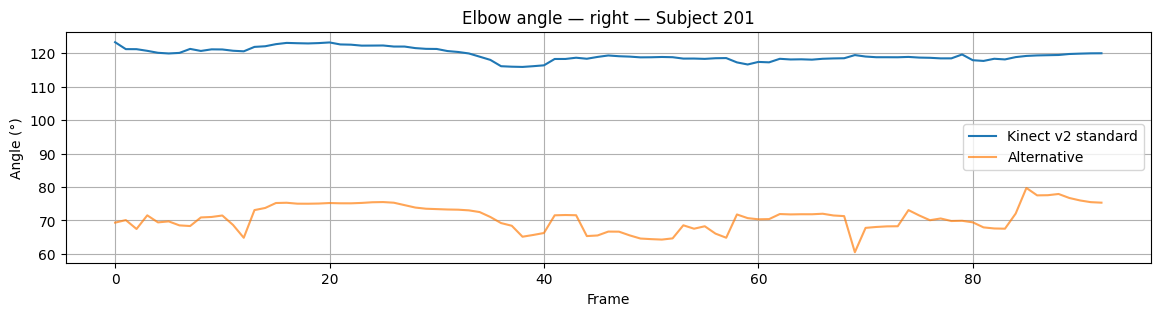

In [10]:
# Paste this as a new cell and run it
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load one file
sample = elbow_files[0]
df = pd.read_csv(sample['path'], header=None).values.astype(float)

print(f"File: {sample['path']}")
print(f"Shape: {df.shape}")
print(f"Side: {sample['side']}, Subject: {sample['subject']}")
print()

# Print first 3 rows to see raw values
print("First 3 rows (raw):")
print(df[:3, :12])  # first 12 columns only
print()

# Try BOTH joint index styles
def angle3(data, j1, j2, j3, stride=3):
    S = data[:, j1*stride:j1*stride+3]
    E = data[:, j2*stride:j2*stride+3]
    W = data[:, j3*stride:j3*stride+3]
    v1 = S - E; v2 = W - E
    n1 = np.linalg.norm(v1,axis=1); n2 = np.linalg.norm(v2,axis=1)
    safe = (n1>1e-6)&(n2>1e-6)
    cos_a = np.where(safe, np.clip((v1*v2).sum(1)/(n1*n2),-1,1), np.nan)
    return np.degrees(np.arccos(cos_a))

# Kinect v2 standard: ShoulderRight=8, ElbowRight=9, WristRight=10
#                     ShoulderLeft=4,  ElbowLeft=5,  WristLeft=6
if sample['side'] == 'right':
    a_v2  = angle3(df, 8, 9, 10, stride=3)   # Kinect v2 standard
    a_alt = angle3(df, 5, 9, 10, stride=3)   # alternative
else:
    a_v2  = angle3(df, 4, 5, 6,  stride=3)
    a_alt = angle3(df, 4, 6, 7,  stride=3)

print(f"Kinect v2 standard: min={np.nanmin(a_v2):.1f}  max={np.nanmax(a_v2):.1f}  NaN={np.isnan(a_v2).sum()}")
print(f"Alternative:        min={np.nanmin(a_alt):.1f}  max={np.nanmax(a_alt):.1f}  NaN={np.isnan(a_alt).sum()}")
print(f"Columns in file: {df.shape[1]}  ({df.shape[1]/3:.0f} joints if 3-col, {df.shape[1]/4:.0f} if 4-col)")

plt.figure(figsize=(14,3))
plt.plot(a_v2,  label='Kinect v2 standard')
plt.plot(a_alt, label='Alternative', alpha=0.7)
plt.ylabel('Angle (°)'); plt.xlabel('Frame')
plt.title(f'Elbow angle — {sample["side"]} — Subject {sample["subject"]}')
plt.legend(); plt.grid(True); plt.show()

In [11]:
# Find which joint triple gives a proper elbow flexion angle
import numpy as np
import pandas as pd

sample = elbow_files[0]
df = pd.read_csv(sample['path'], header=None).values.astype(float)

def angle3(data, j1, j2, j3):
    S = data[:, j1*3:j1*3+3]
    E = data[:, j2*3:j2*3+3]
    W = data[:, j3*3:j3*3+3]
    v1 = S - E; v2 = W - E
    n1 = np.linalg.norm(v1,axis=1); n2 = np.linalg.norm(v2,axis=1)
    safe = (n1>1e-6)&(n2>1e-6)
    cos_a = np.where(safe, np.clip((v1*v2).sum(1)/(n1*n2),-1,1), np.nan)
    return np.degrees(np.arccos(cos_a))

print("Searching for joint triple with range > 40 degrees...\n")
print(f"{'j_shoulder':>12} {'j_elbow':>8} {'j_wrist':>8} {'min':>7} {'max':>7} {'range':>7}")
print("-"*55)

candidates = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js == je or je == jw or js == jw:
                continue
            try:
                a = angle3(df, js, je, jw)
                r = np.nanmax(a) - np.nanmin(a)
                if r > 40:
                    candidates.append((r, js, je, jw, np.nanmin(a), np.nanmax(a)))
            except:
                pass

candidates.sort(reverse=True)
for r, js, je, jw, mn, mx in candidates[:20]:
    print(f"  js={js:2d} je={je:2d} jw={jw:2d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

Searching for joint triple with range > 40 degrees...

  j_shoulder  j_elbow  j_wrist     min     max   range
-------------------------------------------------------
  js=22 je= 6 jw= 3       9.7   175.2   165.5
  js= 3 je= 6 jw=22       9.7   175.2   165.5
  js=20 je= 7 jw= 6      12.0   175.5   163.5
  js= 6 je= 7 jw=20      12.0   175.5   163.5
  js=20 je= 6 jw= 7       4.3   167.7   163.4
  js= 7 je= 6 jw=20       4.3   167.7   163.4
  js= 7 je=22 jw= 3       9.2   172.3   163.1
  js= 3 je=22 jw= 7       9.2   172.3   163.1
  js=22 je= 7 jw= 3       6.5   169.4   162.9
  js= 3 je= 7 jw=22       6.5   169.4   162.9
  js= 6 je=22 jw= 3       4.1   167.0   162.9
  js= 3 je=22 jw= 6       4.1   167.0   162.9
  js= 7 je=22 jw= 2      15.4   177.5   162.1
  js= 2 je=22 jw= 7      15.4   177.5   162.1
  js=22 je= 7 jw=17      15.4   176.0   160.6
  js=17 je= 7 jw=22      15.4   176.0   160.6
  js=22 je= 7 jw= 2       1.8   162.1   160.3
  js= 2 je= 7 jw=22       1.8   162.1   160.3
  js= 

Angle: min=45.1°  max=162.9°  range=117.8°


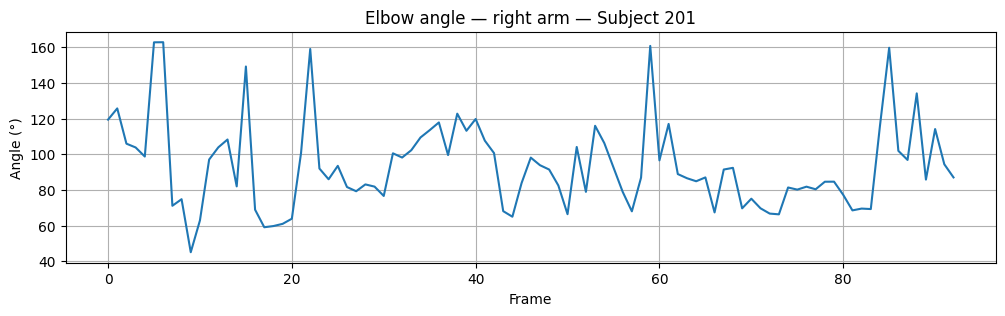

In [12]:
import matplotlib.pyplot as plt

sample = elbow_files[0]
df = pd.read_csv(sample['path'], header=None).values.astype(float)

a = angle3(df, 23, 7, 22)
print(f"Angle: min={a.min():.1f}°  max={a.max():.1f}°  range={a.max()-a.min():.1f}°")

plt.figure(figsize=(12,3))
plt.plot(a)
plt.title(f'Elbow angle — {sample["side"]} arm — Subject {sample["subject"]}')
plt.ylabel('Angle (°)'); plt.xlabel('Frame'); plt.grid(True)
plt.show()

In [13]:
import os
from collections import Counter

all_files = elbow_files  # already filtered to gesture 0 and 1

# show unique suffixes after the 5th underscore
suffixes = []
for f in all_files:
    name = os.path.basename(f['path'])
    parts = name.replace('.txt','').replace('.csv','').split('_')
    suffix = '_'.join(parts[5:]) if len(parts) > 5 else 'NO_SUFFIX'
    suffixes.append(suffix)

print("File name suffixes found:")
for s, count in Counter(suffixes).most_common():
    print(f"  {count:3d}  {s}")

File name suffixes found:
  540  stand
  306  chair
  154  wheelchair
   48  sit


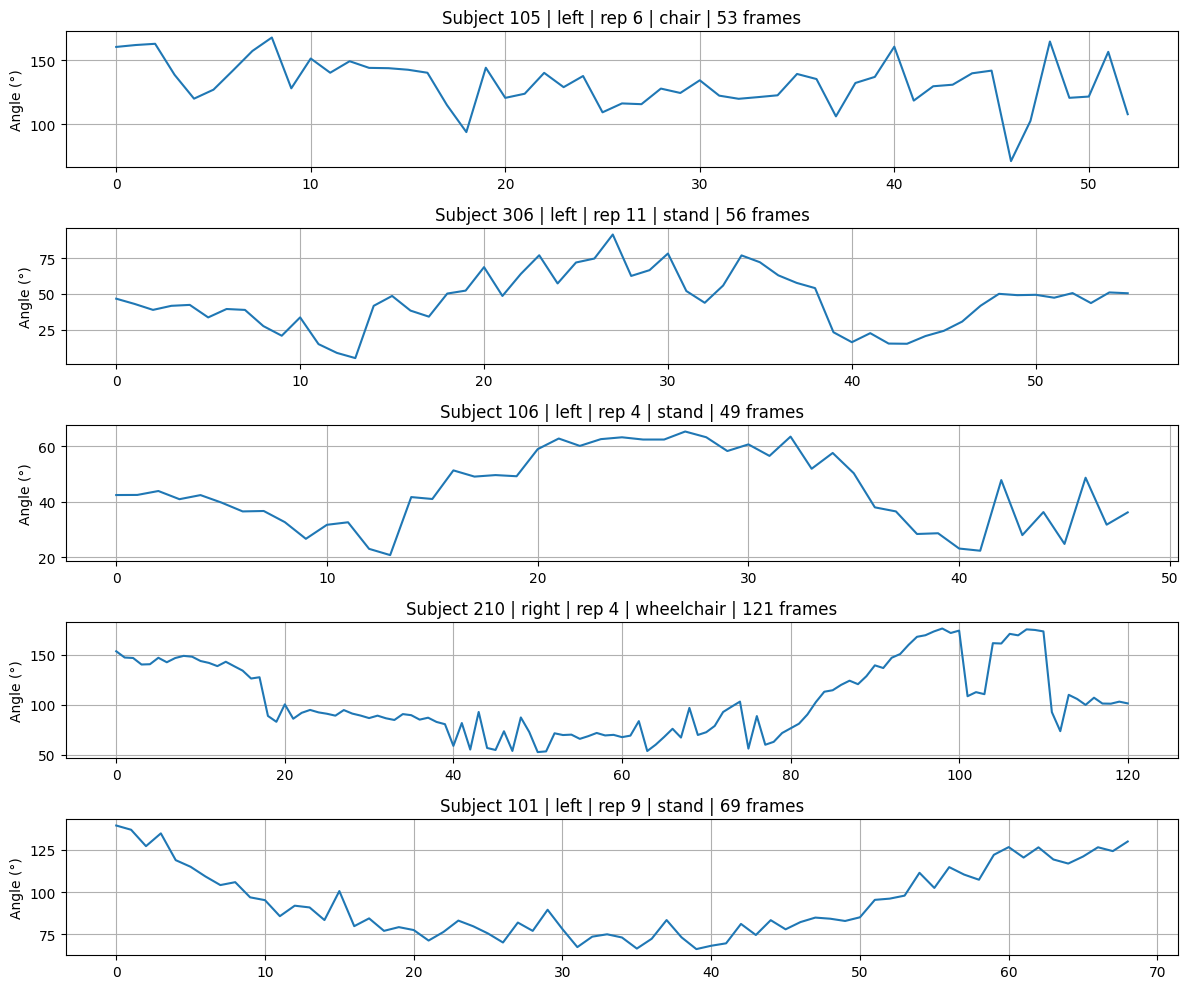

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Plot 5 random rep files and visually confirm each is one rep
sample_files = [f for f in elbow_files if f['correct']=='1'][:5]

fig, axes = plt.subplots(5, 1, figsize=(12, 10))
for ax, info in zip(axes, sample_files):
    data = load_file(info['path'])
    if data is None: continue
    j_s, j_e, j_w = (JOINTS_RIGHT if info['side']=='right' else JOINTS_LEFT)
    a = angle3(data, j_s, j_e, j_w)
    ax.plot(a)
    ax.set_title(f"Subject {info['subject']} | {info['side']} | "
                 f"rep {info['rep_num']} | {info['position']} | "
                 f"{len(a)} frames")
    ax.set_ylabel('Angle (°)')
    ax.grid(True)
plt.tight_layout()
plt.show()

In [15]:
import subprocess, sys
sys.path.insert(0, '/content/repo')
subprocess.run(['pip', 'install', '-q', 'fastdtw'], check=True)

from assessment.dtw import load_template, is_calibrated
t = load_template('/content/repo/template.json')
print('Template calibrated:', is_calibrated(t))
print('Template keys:', list(t.keys()))

Template calibrated: True
Template keys: ['exercise', 'recorded_by', 'calibrated', 'method', 'n_people', 'n_reps', 'n_calibration_reps', 'mean_trajectory', 'std_trajectory', 'mu_dtw', 'sigma_dtw', 'sigma_floor']


In [16]:
import json
with open('/content/repo/template.json') as f:
    t = json.load(f)

print('Exercise:', t.get('exercise'))
print('Recorded by:', t.get('recorded_by'))
print('N reps used:', t.get('n_reps'))
print('N calibration reps:', t.get('n_calibration_reps'))
print('N people:', t.get('n_people'))
print('Note:', t.get('note'))
print('mu_dtw:', t.get('mu_dtw'))
print('sigma_dtw:', t.get('sigma_dtw'))
print('mean_trajectory length:', len(t.get('mean_trajectory', [])))

Exercise: elbow_flexion
Recorded by: your_name
N reps used: 12
N calibration reps: 12
N people: 1
Note: None
mu_dtw: 185.99473204264868
sigma_dtw: 227.47787474534184
mean_trajectory length: 100


In [17]:
# ============================================================
# STEP 8 — Shoulder Abduction: find correct joint indices
# ============================================================
from exercise_state import ShoulderFSM

SHOULDER_LABELS = {'4', '5'}   # 4=abduction left, 5=abduction right

# build shoulder file list
shoulder_files = []
for f in files:
    name = os.path.basename(f).replace('.txt','').replace('.csv','')
    parts = name.split('_')
    if len(parts) < 5:
        continue
    suffix = '_'.join(parts[5:]) if len(parts) > 5 else ''
    if 'Stand-frame' in suffix:
        continue
    if parts[2] in SHOULDER_LABELS:
        shoulder_files.append({
            'path':    f,
            'subject': parts[0],
            'date':    parts[1],
            'gesture': parts[2],
            'rep_num': parts[3],
            'correct': parts[4],
            'position': suffix,
            'side':    'left' if parts[2] == '4' else 'right',
        })

print(f'Shoulder abduction files: {len(shoulder_files)}')
print(pd.DataFrame(shoulder_files)['side'].value_counts())

# ============================================================
# STEP 9 — Brute force joint search on a shoulder file
# ============================================================
# shoulder abduction angle = hip - shoulder - elbow
# expected range: 0-150 degrees (arm at side to fully raised)

sample_s = shoulder_files[0]
print(f"\nSample: {os.path.basename(sample_s['path'])}")
print(f"Side: {sample_s['side']}, Subject: {sample_s['subject']}")
df_s = load_file(sample_s['path'])
print(f"Shape: {df_s.shape}")

candidates_s = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js==je or je==jw or js==jw: continue
            try:
                a = angle3(df_s, js, je, jw)
                mn, mx = np.nanmin(a), np.nanmax(a)
                r = mx - mn
                # shoulder abduction: expect range 60-150 deg
                # and angle should stay below 170 (not elbow-like)
                if r > 60 and mx < 170:
                    candidates_s.append((r, js, je, jw, mn, mx))
            except: pass

candidates_s.sort(reverse=True)
print(f"\n{'js':>5} {'je':>5} {'jw':>5}  {'min':>7} {'max':>7} {'range':>7}")
for r, js, je, jw, mn, mx in candidates_s[:10]:
    print(f"  {js:3d}  {je:3d}  {jw:3d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

Shoulder abduction files: 1048
side
left     544
right    504
Name: count, dtype: int64

Sample: 105_18_4_1_1_stand.txt
Side: left, Subject: 105
Shape: (54, 75)

   js    je    jw      min     max   range
   23   24   19       4.3   169.5   165.2
   19   24   23       4.3   169.5   165.2
   24   23   18       7.6   168.5   160.8
   18   23   24       7.6   168.5   160.8
   23    7   22       7.2   166.8   159.6
   22    7   23       7.2   166.8   159.6
   24   11   23      10.2   168.4   158.2
   23   11   24      10.2   168.4   158.2
   18   11   10       6.2   163.8   157.6
   10   11   18       6.2   163.8   157.6


File: 105_18_4_1_1_stand.txt

   js    je    jw      min     max   range
   18   23   11       4.3   149.8   145.5
   11   23   18       4.3   149.8   145.5
   22    6   16       8.3   148.9   140.5
   16    6   22       8.3   148.9   140.5
   16   22    7       1.1   141.7   140.5
    7   22   16       1.1   141.7   140.5
   19    8   11      10.1   147.6   137.4
   11    8   19      10.1   147.6   137.4
   15   23   10       7.2   143.9   136.7
   10   23   15       7.2   143.9   136.7


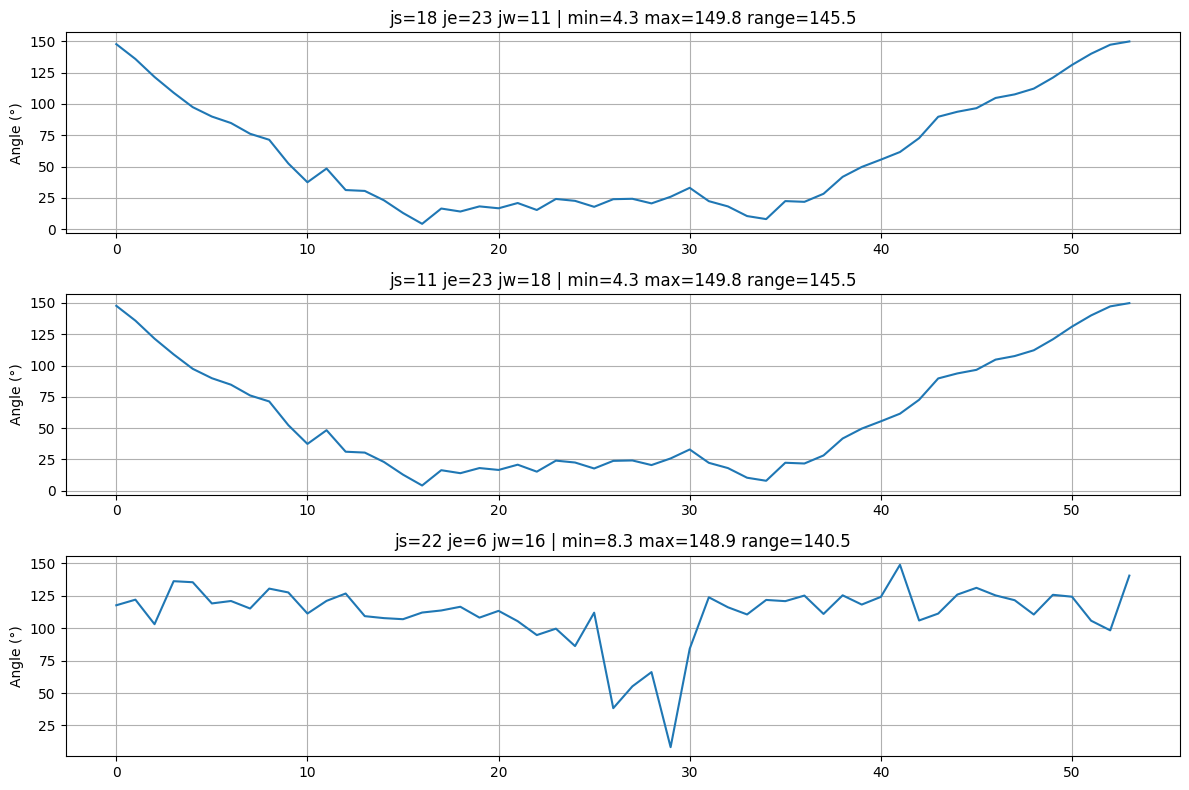

In [18]:
# Find shoulder abduction joints in IRDS
# Shoulder abduction: arm raises to side
# Signal should: start low (5-20deg), rise to 60-130deg, come back down
# Key difference from elbow: max should NOT exceed 150deg

sample_s = [f for f in shoulder_files if f['side']=='left'][0]
df_s = load_file(sample_s['path'])
print(f"File: {os.path.basename(sample_s['path'])}")

candidates_s = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js==je or je==jw or js==jw: continue
            try:
                a = angle3(df_s, js, je, jw)
                mn, mx = np.nanmin(a), np.nanmax(a)
                r = mx - mn
                # tighter filter for shoulder abduction
                if r > 40 and mn < 35 and mx < 150:
                    candidates_s.append((r, js, je, jw, mn, mx))
            except: pass

candidates_s.sort(reverse=True)
print(f"\n{'js':>5} {'je':>5} {'jw':>5}  {'min':>7} {'max':>7} {'range':>7}")
for r, js, je, jw, mn, mx in candidates_s[:10]:
    print(f"  {js:3d}  {je:3d}  {jw:3d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

# plot top 3 candidates
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3,1, figsize=(12,8))
for ax, (r, js, je, jw, mn, mx) in zip(axes, candidates_s[:3]):
    a = angle3(df_s, js, je, jw)
    ax.plot(a)
    ax.set_title(f'js={js} je={je} jw={jw} | min={mn:.1f} max={mx:.1f} range={r:.1f}')
    ax.set_ylabel('Angle (°)'); ax.grid(True)
plt.tight_layout(); plt.show()

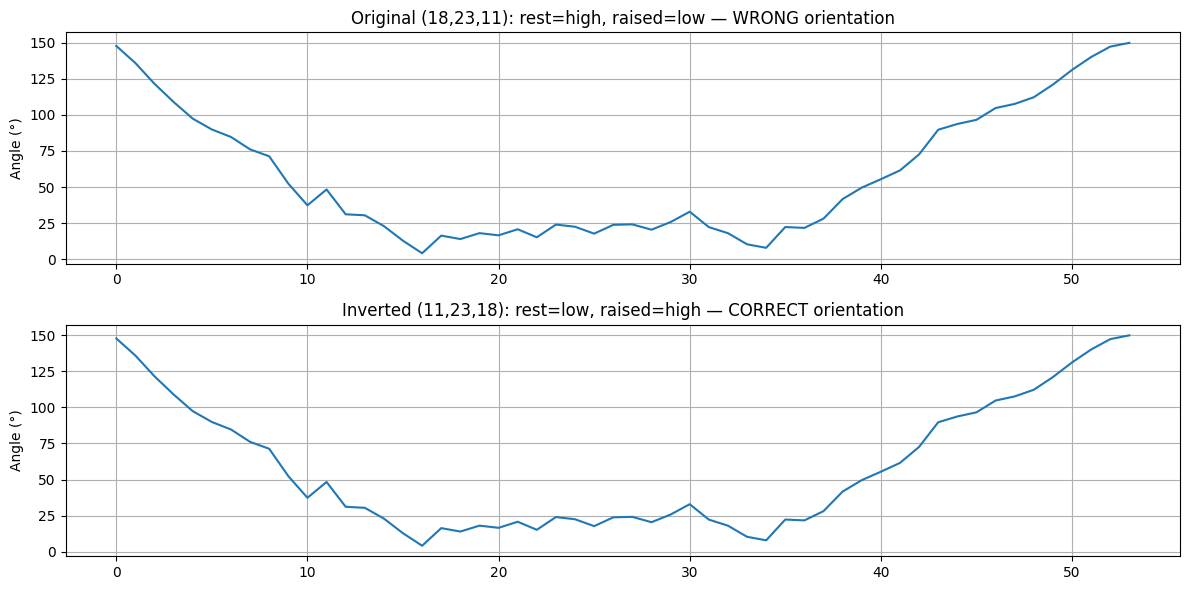

Inverted: min=4.3 max=149.8


In [19]:
# Best joint triple for LEFT shoulder abduction in IRDS
# Swap js and jw to get the correct orientation (low=rest, high=raised)
JOINTS_LEFT_SHOULDER  = (11, 23, 18)   # swapped from (18, 23, 11)
JOINTS_RIGHT_SHOULDER = None           # find from a right arm file next

# Verify the inversion works
sample_s = [f for f in shoulder_files if f['side']=='left'][0]
df_s = load_file(sample_s['path'])
a_original = angle3(df_s, 18, 23, 11)
a_inverted = angle3(df_s, 11, 23, 18)

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(a_original)
axes[0].set_title('Original (18,23,11): rest=high, raised=low — WRONG orientation')
axes[0].set_ylabel('Angle (°)'); axes[0].grid(True)
axes[1].plot(a_inverted)
axes[1].set_title('Inverted (11,23,18): rest=low, raised=high — CORRECT orientation')
axes[1].set_ylabel('Angle (°)'); axes[1].grid(True)
plt.tight_layout(); plt.show()

print(f'Inverted: min={a_inverted.min():.1f} max={a_inverted.max():.1f}')

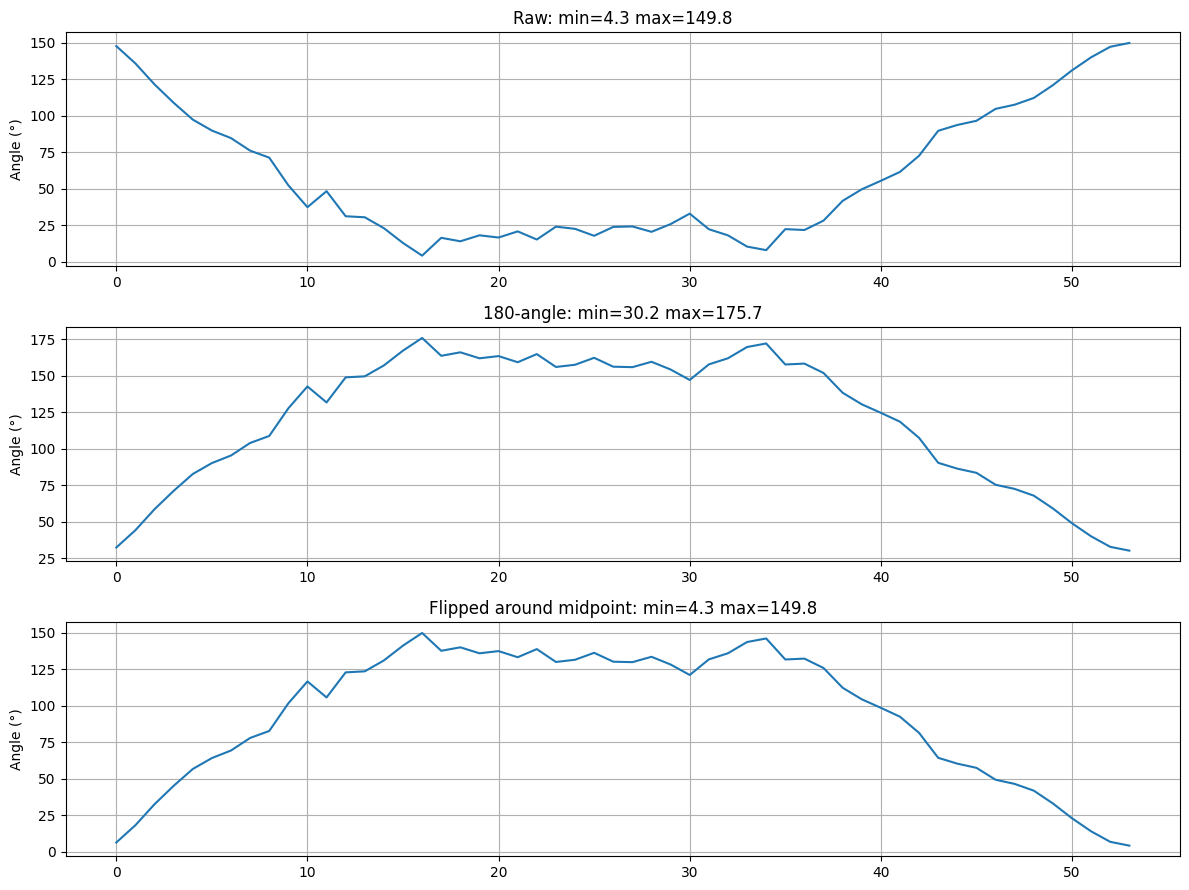

Raw:     min=4.3  max=149.8
180-raw: min=30.2  max=175.7
Flipped: min=4.3  max=149.8


In [20]:
# Invert the angle: 180 - angle
# This converts: rest=150° → rest=30°, raised=10° → raised=170°
# But that's too high. Use the actual range instead.

sample_s = [f for f in shoulder_files if f['side']=='left'][0]
df_s = load_file(sample_s['path'])
a_raw = angle3(df_s, 18, 23, 11)

# Option 1: 180 - angle
a_inv = 180 - a_raw

# Option 2: flip around midpoint
midpoint = (a_raw.max() + a_raw.min()) / 2
a_flip = 2 * midpoint - a_raw

import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(a_raw);  axes[0].set_title(f'Raw: min={a_raw.min():.1f} max={a_raw.max():.1f}'); axes[0].grid(True)
axes[1].plot(a_inv);  axes[1].set_title(f'180-angle: min={a_inv.min():.1f} max={a_inv.max():.1f}'); axes[1].grid(True)
axes[2].plot(a_flip); axes[2].set_title(f'Flipped around midpoint: min={a_flip.min():.1f} max={a_flip.max():.1f}'); axes[2].grid(True)
for ax in axes: ax.set_ylabel('Angle (°)')
plt.tight_layout(); plt.show()

print(f'Raw:     min={a_raw.min():.1f}  max={a_raw.max():.1f}')
print(f'180-raw: min={a_inv.min():.1f}  max={a_inv.max():.1f}')
print(f'Flipped: min={a_flip.min():.1f}  max={a_flip.max():.1f}')

In [21]:
# Find right arm shoulder joint indices
sample_right = [f for f in shoulder_files if f['side']=='right'][0]
print(f"File: {os.path.basename(sample_right['path'])}")
df_r = load_file(sample_right['path'])

candidates_r = []
for js in range(25):
    for je in range(25):
        for jw in range(25):
            if js==je or je==jw or js==jw: continue
            try:
                a = angle3(df_r, js, je, jw)
                mn, mx = np.nanmin(a), np.nanmax(a)
                r = mx - mn
                if r > 60 and mn < 40 and mx < 165:
                    candidates_r.append((r, js, je, jw, mn, mx))
            except: pass

candidates_r.sort(reverse=True)
print(f"\n{'js':>5} {'je':>5} {'jw':>5}  {'min':>7} {'max':>7} {'range':>7}")
for r, js, je, jw, mn, mx in candidates_r[:10]:
    print(f"  {js:3d}  {je:3d}  {jw:3d}   {mn:7.1f} {mx:7.1f} {r:7.1f}")

File: 104_18_5_1_1_stand.txt

   js    je    jw      min     max   range
    7   22    0      21.6   162.7   141.1
    0   22    7      21.6   162.7   141.1
   24   11   15      21.8   162.8   141.0
   15   11   24      21.8   162.8   141.0
   24   11   18      10.3   150.6   140.3
   18   11   24      10.3   150.6   140.3
   15   24   11      16.1   156.4   140.3
   11   24   15      16.1   156.4   140.3
   24   11   17      19.7   159.8   140.2
   17   11   24      19.7   159.8   140.2


In [22]:
# ============================================================
# STEP 10 — ShoulderFSM OBO benchmark (left arm only)
# ============================================================
from exercise_state import ShoulderFSM

JOINTS_LEFT_SHOULDER = (18, 23, 11)

def shoulder_angle_left(data):
    a = angle3(data, 18, 23, 11)
    mid = (np.nanmax(a) + np.nanmin(a)) / 2
    return 2 * mid - a   # flip to correct orientation

def run_shoulder_fsm(signal, fps=30.0):
    fsm = ShoulderFSM()
    cal_ok = fsm.calibrate_from_signal(signal, fps=fps)
    for i, a in enumerate(signal):
        if np.isfinite(a):
            fsm.update(a, i/fps)
    fsm.flush(len(signal)/fps)
    return fsm.rep_count, len(fsm.incomplete_attempts), cal_ok

rows_s = []
skipped_s = 0

for info in shoulder_files:
    if info['side'] != 'left':
        continue
    data = load_file(info['path'])
    if data is None:
        skipped_s += 1
        continue
    signal = shoulder_angle_left(data)
    counted, incomplete, cal_ok = run_shoulder_fsm(signal, VIDEO_FPS)
    rows_s.append(dict(
        subject=info['subject'], side=info['side'],
        correct=info['correct'], position=info['position'],
        gt=1, counted=counted, incomplete=incomplete,
        detected=counted+incomplete, calibrated=cal_ok,
        n_frames=len(signal),
        angle_min=np.nanmin(signal), angle_max=np.nanmax(signal),
    ))

print(f'Skipped: {skipped_s}')
df_s = pd.DataFrame(rows_s)
df_s['err']     = (df_s['counted']  - df_s['gt']).abs()
df_s['err_det'] = (df_s['detected'] - df_s['gt']).abs()

print(f'Processed: {len(df_s)} left shoulder files')
print(f'Calibration OK: {df_s["calibrated"].sum()}/{len(df_s)}')
print(f'Zero count: {(df_s["counted"]==0).sum()}/{len(df_s)}')
print()
print('='*85)
print('IRDS — ShoulderFSM left arm shoulder abduction (GT=1 per file)')
print('='*85)

def summary_s(d, label=''):
    n = len(d)
    if n == 0: return
    print(f'{label:35s} n={n:4d}  MAE={(d["err"].mean()):.2f}  '
          f'OBO={100*(d["err"]<=1).mean():.1f}%  '
          f'Exact={100*(d["err"]==0).mean():.1f}%  '
          f'OBO_det={100*(d["err_det"]<=1).mean():.1f}%  '
          f'Zero={100*(d["counted"]==0).mean():.1f}%')

summary_s(df_s,                        'ALL left shoulder')
summary_s(df_s[df_s.correct=='1'],     'Correct reps')
summary_s(df_s[df_s.correct=='2'],     'Incorrect reps')
summary_s(df_s[df_s.position=='stand'],'Standing')
summary_s(df_s[df_s.position=='chair'],'Chair')
summary_s(df_s[df_s.position=='wheelchair'], 'Wheelchair')

ShoulderFSM calibrated: RAISE=51°  REST=18°  range=130°
ShoulderFSM calibrated: RAISE=64°  REST=31°  range=131°
ShoulderFSM calibrated: RAISE=68°  REST=57°  range=46°
ShoulderFSM calibrated: RAISE=84°  REST=67°  range=68°
ShoulderFSM calibrated: RAISE=61°  REST=28°  range=129°
ShoulderFSM calibrated: RAISE=61°  REST=40°  range=84°
ShoulderFSM calibrated: RAISE=114°  REST=102°  range=50°
ShoulderFSM calibrated: RAISE=90°  REST=65°  range=102°
ShoulderFSM calibrated: RAISE=77°  REST=43°  range=136°
ShoulderFSM calibrated: RAISE=56°  REST=20°  range=145°
ShoulderFSM calibrated: RAISE=44°  REST=25°  range=77°
ShoulderFSM calibrated: RAISE=69°  REST=38°  range=124°
ShoulderFSM calibrated: RAISE=84°  REST=64°  range=80°
ShoulderFSM calibrated: RAISE=55°  REST=19°  range=143°
ShoulderFSM calibrated: RAISE=36°  REST=17°  range=78°
ShoulderFSM calibrated: RAISE=39°  REST=17°  range=89°
ShoulderFSM calibrated: RAISE=44°  REST=19°  range=101°
ShoulderFSM calibrated: RAISE=69°  REST=57°  range=46°

In [23]:
# ============================================================
# FIX 1 — Real anatomical joints (replaces the brute-force joint search)
# ============================================================
# Needs: `files` from Step 2 and the repo clone from Step 3.
import os, numpy as np, pandas as pd
from exercise_state import ElbowFSM, ShoulderFSM

# Standard Kinect v2 joint order (25 joints x 3 coordinates = 75 columns)
K = dict(SpineBase=0, SpineMid=1, Neck=2, Head=3,
         ShoulderLeft=4, ElbowLeft=5, WristLeft=6, HandLeft=7,
         ShoulderRight=8, ElbowRight=9, WristRight=10, HandRight=11,
         HipLeft=12, KneeLeft=13, AnkleLeft=14, FootLeft=15,
         HipRight=16, KneeRight=17, AnkleRight=18, FootRight=19,
         SpineShoulder=20)

# The same angles the app measures (overlay.JOINTS): the angle is at the middle joint
TRIPLES = {
    'elbow':    {'left':  (K['ShoulderLeft'],  K['ElbowLeft'],  K['WristLeft']),
                 'right': (K['ShoulderRight'], K['ElbowRight'], K['WristRight'])},
    'shoulder': {'left':  (K['HipLeft'],  K['ShoulderLeft'],  K['ElbowLeft']),
                 'right': (K['HipRight'], K['ShoulderRight'], K['ElbowRight'])},
}
# IRDS gesture label -> (exercise, side the LABEL says)
GESTURES = {'0': ('elbow', 'left'), '1': ('elbow', 'right'),
            '4': ('shoulder', 'left'), '5': ('shoulder', 'right')}
FPS = 30.0


def load_file(path):
    """75-column skeleton file -> float array, or None if it is another format."""
    for sep in [',', r'\s+']:
        try:
            df = pd.read_csv(path, header=None, sep=sep, engine='python')
            if df.shape[1] == 75:
                return df.values.astype(float)
        except Exception:
            pass
    return None


def joint(data, j):
    return data[:, j * 3:j * 3 + 3]


def angle3(data, a, b, c):
    """Angle at joint b (degrees) for every frame, in 3D."""
    v1, v2 = joint(data, a) - joint(data, b), joint(data, c) - joint(data, b)
    n1, n2 = np.linalg.norm(v1, axis=1), np.linalg.norm(v2, axis=1)
    ok = (n1 > 1e-6) & (n2 > 1e-6)
    cos = np.where(ok, np.clip((v1 * v2).sum(1) / np.where(ok, n1 * n2, 1.0), -1, 1), np.nan)
    return np.degrees(np.arccos(cos))


# ---- load every elbow / shoulder-abduction rep once (the folder holds each recording twice)
recs, seen = [], set()
for f in files:
    name = os.path.basename(f).rsplit('.', 1)[0]
    parts = name.split('_')
    if len(parts) < 5 or parts[2] not in GESTURES or name in seen:
        continue
    position = '_'.join(parts[5:])
    if 'Stand-frame' in position:
        continue
    data = load_file(f)
    if data is None or len(data) < 10:
        continue
    seen.add(name)
    exercise, label_side = GESTURES[parts[2]]
    recs.append(dict(name=name, subject=parts[0], date=parts[1], gesture=parts[2],
                     rep_num=int(parts[3]), correct=parts[4], position=position,
                     exercise=exercise, label_side=label_side, data=data))

print(f'Loaded {len(recs)} rep files')
print(pd.DataFrame([{k: r[k] for k in ("gesture", "exercise", "label_side")} for r in recs]).value_counts().sort_index())

# ---- check the joint order really is standard Kinect v2
d = recs[0]['data']
y = [np.nanmedian(joint(d, K[n])[:, 1]) for n in ('SpineBase', 'SpineMid', 'Neck', 'Head')]
upper = np.nanmedian(np.linalg.norm(joint(d, K['ShoulderLeft']) - joint(d, K['ElbowLeft']), axis=1))
fore  = np.nanmedian(np.linalg.norm(joint(d, K['ElbowLeft']) - joint(d, K['WristLeft']), axis=1))
print('\nJoint order check')
print('  spine base -> head heights rise:', np.round(y, 2), 'OK' if y == sorted(y) else 'NOT OK')
print(f'  upper arm {upper:.2f} m, forearm {fore:.2f} m',
      'OK' if 0.15 < upper < 0.45 and 0.15 < fore < 0.40 else 'NOT OK')
print('If either line says NOT OK, stop: the joint numbers in K are wrong for these files.')

Loaded 1048 rep files
gesture  exercise  label_side
0        elbow     left          251
1        elbow     right         273
4        shoulder  left          272
5        shoulder  right         252
Name: count, dtype: int64

Joint order check
  spine base -> head heights rise: [-0.03  0.25  0.52  0.65] OK
  upper arm 0.21 m, forearm 0.19 m OK
If either line says NOT OK, stop: the joint numbers in K are wrong for these files.


gesture  exercise  label     n  median L range  median R range  L moves more  -> use
      0     elbow   left   251             3.4           119.9            5%  -> right   (label is mirrored)
      1     elbow  right   273           119.2             2.6           98%  -> left   (label is mirrored)
      4  shoulder   left   272             5.2           123.9            9%  -> right   (label is mirrored)
      5  shoulder  right   252           126.6             4.4          100%  -> left   (label is mirrored)

A clear result is ~100% or ~0% in the last column, with one range much bigger than the other.


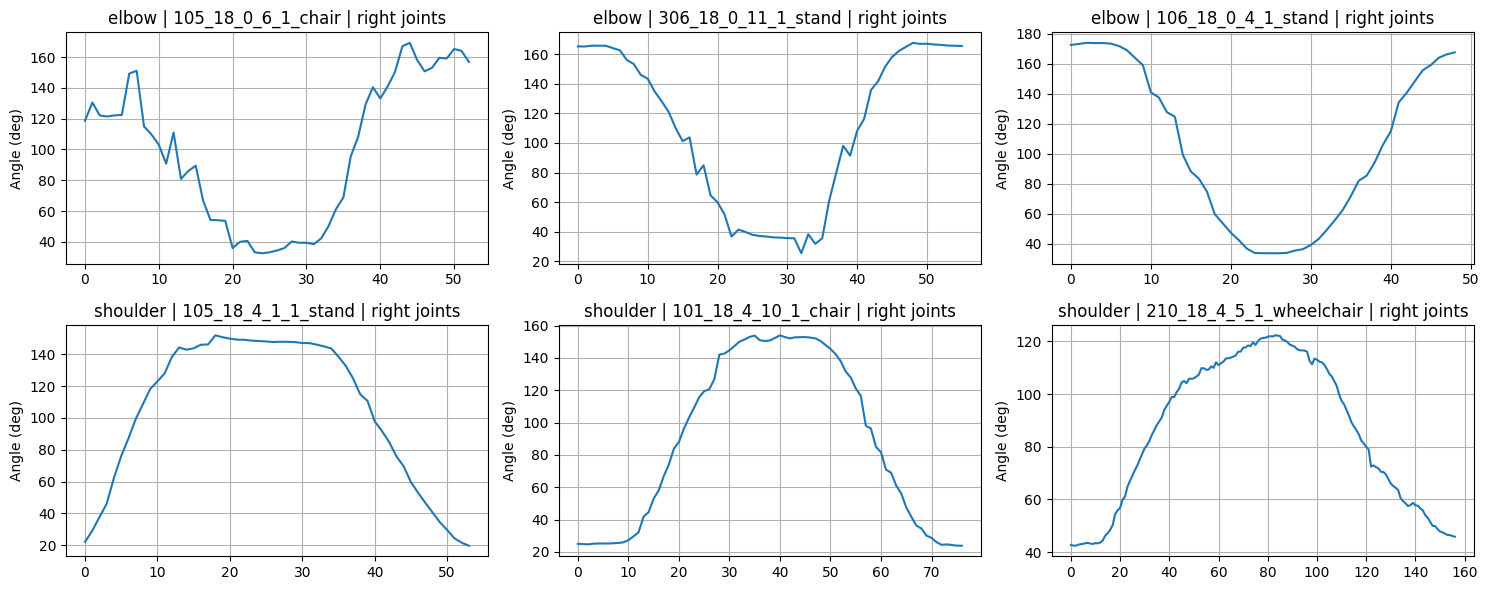

Expected shape: elbow starts HIGH (~150+), dips, returns. Shoulder starts LOW (~10-30), rises, returns.


In [24]:
# ============================================================
# FIX 2 — Which arm really moves for each gesture label?
# ============================================================
# The labels looked mirrored in the old joint search, so measure it instead of assuming.
rows = []
for r in recs:
    rng = {}
    for side in ('left', 'right'):
        a = angle3(r['data'], *TRIPLES[r['exercise']][side])
        rng[side] = np.nanpercentile(a, 95) - np.nanpercentile(a, 5)
    rows.append(dict(gesture=r['gesture'], exercise=r['exercise'], label_side=r['label_side'],
                     left_range=rng['left'], right_range=rng['right'],
                     left_moves_more=rng['left'] > rng['right']))
side_df = pd.DataFrame(rows)

MOVING_SIDE = {}
print(f"{'gesture':>7} {'exercise':>9} {'label':>6} {'n':>5} {'median L range':>15} {'median R range':>15} {'L moves more':>13}  -> use")
for g, grp in side_df.groupby('gesture'):
    share_left = grp['left_moves_more'].mean()
    MOVING_SIDE[g] = 'left' if share_left >= 0.5 else 'right'
    flag = '' if MOVING_SIDE[g] == grp['label_side'].iloc[0] else '   (label is mirrored)'
    print(f"{g:>7} {grp['exercise'].iloc[0]:>9} {grp['label_side'].iloc[0]:>6} {len(grp):5d} "
          f"{grp['left_range'].median():15.1f} {grp['right_range'].median():15.1f} "
          f"{100 * share_left:12.0f}%  -> {MOVING_SIDE[g]}{flag}")
print('\nA clear result is ~100% or ~0% in the last column, with one range much bigger than the other.')

for r in recs:
    r['side'] = MOVING_SIDE[r['gesture']]
    r['angle'] = angle3(r['data'], *TRIPLES[r['exercise']][r['side']])

# look at a few real signals before trusting any number
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for row, ex in zip(axes, ('elbow', 'shoulder')):
    for ax, r in zip(row, [x for x in recs if x['exercise'] == ex and x['correct'] == '1'][:3]):
        ax.plot(r['angle']); ax.grid(True); ax.set_ylabel('Angle (deg)')
        ax.set_title(f"{ex} | {r['name']} | {r['side']} joints")
plt.tight_layout(); plt.show()
print('Expected shape: elbow starts HIGH (~150+), dips, returns. Shoulder starts LOW (~10-30), rises, returns.')

In [25]:
# ============================================================
# FIX 3 — One rep per file: report Exact, not OBO
# ============================================================
# Each file is one rep (true count = 1). OBO passes on a count of 0, so it is
# always 100% here. What matters: counted exactly 1, counted 0, counted 2+.
def new_fsm(exercise):
    return ShoulderFSM() if exercise == 'shoulder' else ElbowFSM()


def run_one(exercise, signal, calib_signal=None):
    """Returns (reps counted, list of 'not counted' reasons, calibrated?)."""
    import io, contextlib
    fsm = new_fsm(exercise)
    cal = False
    if calib_signal is not None:
        with contextlib.redirect_stdout(io.StringIO()):      # hide the per-file print
            cal = fsm.calibrate_from_signal(calib_signal, fps=FPS)
    for i, a in enumerate(np.asarray(signal, float)):
        fsm.update(a, i / FPS)
    fsm.flush(len(signal) / FPS)
    return fsm.rep_count, [x.get('reason') for x in fsm.incomplete_attempts], cal


rows = []
for r in recs:
    for mode in ('default thresholds', 'calibrated on the same file'):
        n, reasons, cal = run_one(r['exercise'], r['angle'],
                                  r['angle'] if mode.startswith('calibrated') else None)
        rows.append(dict(exercise=r['exercise'], side=r['side'], correct=r['correct'],
                         position=r['position'], mode=mode, counted=n,
                         incomplete=len(reasons), reasons=','.join(reasons),
                         rom=np.nanmax(r['angle']) - np.nanmin(r['angle'])))
single = pd.DataFrame(rows)


def table(d, label):
    if len(d) == 0:
        return
    print(f"{label:42s} n={len(d):4d}  Exact={100 * (d.counted == 1).mean():5.1f}%  "
          f"Zero={100 * (d.counted == 0).mean():5.1f}%  Two+={100 * (d.counted >= 2).mean():5.1f}%  "
          f"Seen (counted or flagged)={100 * ((d.counted + d.incomplete) >= 1).mean():5.1f}%")


for ex in ('elbow', 'shoulder'):
    for mode in ('default thresholds', 'calibrated on the same file'):
        d = single[(single.exercise == ex) & (single['mode'] == mode)]
        print('=' * 118); print(f'IRDS {ex} | single-rep files | {mode}'); print('=' * 118)
        table(d, 'ALL')
        table(d[d.correct == '1'], 'Correct reps')
        table(d[d.correct != '1'], 'Incorrect reps')
        for s in ('left', 'right'):
            table(d[d.side == s], f'{s} joints')
        for p in ('stand', 'chair', 'wheelchair', 'sit'):
            table(d[d.position == p], p)
        zero = d[(d.counted == 0)]
        if len(zero):
            print('  Why zero:', zero['reasons'].replace('', 'nothing detected').value_counts().to_dict(),
                  f"| median ROM of zero files {zero.rom.median():.0f} deg vs {d[d.counted == 1].rom.median():.0f} deg counted")
        print()

IRDS elbow | single-rep files | default thresholds
ALL                                        n= 524  Exact= 78.4%  Zero= 13.7%  Two+=  7.8%  Seen (counted or flagged)= 94.8%
Correct reps                               n= 435  Exact= 88.5%  Zero=  3.9%  Two+=  7.6%  Seen (counted or flagged)= 98.6%
Incorrect reps                             n=  89  Exact= 29.2%  Zero= 61.8%  Two+=  9.0%  Seen (counted or flagged)= 76.4%
left joints                                n= 273  Exact= 78.4%  Zero= 12.8%  Two+=  8.8%  Seen (counted or flagged)= 94.1%
right joints                               n= 251  Exact= 78.5%  Zero= 14.7%  Two+=  6.8%  Seen (counted or flagged)= 95.6%
stand                                      n= 270  Exact= 76.7%  Zero= 16.3%  Two+=  7.0%  Seen (counted or flagged)= 94.4%
chair                                      n= 153  Exact= 89.5%  Zero=  2.0%  Two+=  8.5%  Seen (counted or flagged)= 98.7%
wheelchair                                 n=  77  Exact= 58.4%  Zero= 31.2%  Two

In [26]:
# ============================================================
# FIX 4 — Session test: several reps in a row (OBO means something here)
# ============================================================
# Closer to the app: join one subject's CORRECT reps of one gesture into a session,
# calibrate on the first rep (like the CALIB phase), then count the rest.
MIN_REPS = 4
rows = []
groups = {}
for r in recs:
    if r['correct'] == '1':
        groups.setdefault((r['subject'], r['date'], r['gesture'], r['position']), []).append(r)

for (subject, date, gesture, position), reps in groups.items():
    reps = sorted(reps, key=lambda x: x['rep_num'])
    if len(reps) < MIN_REPS:
        continue
    session = np.concatenate([x['angle'] for x in reps[1:]])
    gt = len(reps) - 1
    n, reasons, cal = run_one(reps[0]['exercise'], session, calib_signal=reps[0]['angle'])
    rows.append(dict(exercise=reps[0]['exercise'], side=reps[0]['side'], subject=subject,
                     position=position, gt=gt, counted=n, flagged=len(reasons), calibrated=cal))
sess = pd.DataFrame(rows)
sess['err'] = (sess.counted - sess['gt']).abs()


def session_table(d, label):
    if len(d) == 0:
        return
    print(f"{label:28s} sessions={len(d):3d}  reps={d['gt'].sum():4d}  counted={d.counted.sum():4d} "
          f"({100 * d.counted.sum() / d['gt'].sum():5.1f}%)  flagged not-counted={d.flagged.sum():4d}  "
          f"MAE={d.err.mean():.2f}  Exact={100 * (d.err == 0).mean():5.1f}%  OBO={100 * (d.err <= 1).mean():5.1f}%")


for ex in ('elbow', 'shoulder'):
    d = sess[sess.exercise == ex]
    print('=' * 125); print(f'IRDS {ex} | sessions of correct reps, calibrated on the first rep'); print('=' * 125)
    session_table(d, 'ALL')
    for s in ('left', 'right'):
        session_table(d[d.side == s], f'{s} joints')
    for p in ('stand', 'chair', 'wheelchair', 'sit'):
        session_table(d[d.position == p], p)
    print(f"  sessions where calibration failed: {(~d.calibrated).sum()}")
    print()
print('Note: reps are separate files joined end to end, so there can be a small jump at each join.')/

IRDS elbow | sessions of correct reps, calibrated on the first rep
ALL                          sessions= 68  reps= 347  counted= 312 ( 89.9%)  flagged not-counted=  51  MAE=0.51  Exact= 77.9%  OBO= 89.7%
left joints                  sessions= 34  reps= 180  counted= 161 ( 89.4%)  flagged not-counted=  25  MAE=0.56  Exact= 76.5%  OBO= 91.2%
right joints                 sessions= 34  reps= 167  counted= 151 ( 90.4%)  flagged not-counted=  26  MAE=0.47  Exact= 79.4%  OBO= 88.2%
stand                        sessions= 32  reps= 168  counted= 154 ( 91.7%)  flagged not-counted=  18  MAE=0.44  Exact= 84.4%  OBO= 93.8%
chair                        sessions= 24  reps= 119  counted= 115 ( 96.6%)  flagged not-counted=   8  MAE=0.17  Exact= 83.3%  OBO=100.0%
wheelchair                   sessions=  8  reps=  40  counted=  25 ( 62.5%)  flagged not-counted=  24  MAE=1.88  Exact= 37.5%  OBO= 50.0%
sit                          sessions=  4  reps=  20  counted=  18 ( 90.0%)  flagged not-counted=   1  MA